# THỰC HÀNH: CÁC GIẢI THUẬT PHÂN LOẠI CƠ BẢN
Notebook thực hiện lại toàn bộ code mẫu trong file *Lab - Thuật toán phân loại* và các bài tập thực hành.

**Ghi chú:** dữ liệu *Default of Credit Card Clients* (file Kaggle `default_of_credit_card_clients.csv`) đã được tiền xử lý thành `data.csv` bằng `prep_credit.py` (đổi `PAY_0` → `PAY_1`, tạo `EDUCATION_CAT` và các cột one-hot) để khớp với cấu trúc cột mà bài lab sử dụng. Các chỗ phải chỉnh nhỏ để chạy với scikit-learn hiện tại được ghi chú bằng `# [Chỉnh]`.

## 2.2. GIẢI THUẬT 2: SUPPORT VECTOR MACHINE (SVM)
### 2.2.2. Bài làm mẫu — Bài toán 1: dữ liệu Iris
#### Nhiệm vụ 1: Xây dựng mô hình SVM để phân loại hoa
**1. Tải dữ liệu, xem thông tin các feature, chuẩn bị dữ liệu**

In [21]:
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
# Download&Load dữ liệu iris từ datasets của scikit-learn
iris = datasets.load_iris()
# Hiển thị mô ta dữ liệu, chỉ có trong các bộ dữ liệu chuẩn và mở để học tập và nghiên cứu
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [22]:
# Từ tập dữ liệu ban đầu, tách lấy ma trận biểu diễn các đặc trưng và nhãn.
data = iris.data
target = iris.target
# TODO: Chia dữ liệu và nhãn thành 2 tập dữ liệu huấn luyện và dữ liệu kiểm tra theo tỉ lệ 80:20
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size = 0.2, random_state=101)

**2. Tạo mô hình SVM với dữ liệu đã chuẩn bị**

In [23]:
from sklearn import svm
# khởi tạo mô hình phân lớp
clf = svm.SVC()
# Sử dụng phương thức 'fit' để huấn luyện mô hình với dữ liệu huấn luyện và nhãn huấn luyện
# fit (X,Y) với X là tập các đối tượng, Y là tập nhãn tương ứng của đối tượng.
clf.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


**3. Đánh giá độ chính xác của mô hình**

In [24]:
# Tính độ chính xác trên tập huấn luyện và tập kiểm tra
train_acc = clf.score(X_train,y_train)
val_acc = clf.score(X_test,y_test)
print('Training accuracy: {}'.format(train_acc))
print('Validation accuracy: {}'.format(val_acc))

Training accuracy: 0.95
Validation accuracy: 0.9666666666666667


**4. Tìm tham số kernel tối ưu cho mô hình SVM**

In [25]:
# best_svm, best_val_acc và best_kernel lần lượt là các biến lưu mô hình tốt nhất,
# độ chính xác cao nhất trên tập kiểm tra và kernel tốt nhất
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
best_svm = None
best_val_acc = -1
best_kernel = None
# Huấn luyện các mô hình dựa trên dữ liệu huấn luyện và tham số kernel
# Tính toán độ chính xác trên tập huấn luyện và tập kiểm tra để tìm được mô hình tốt nhất
for i in range(4):
    clf = svm.SVC(kernel=kernels[i], probability=True)
    clf.fit(X_train, y_train)
    tmp_val_acc = clf.score(X_test, y_test)
    print("kernel = {:8s} validation accuracy = {:.4f}".format(kernels[i], tmp_val_acc))
    if (tmp_val_acc > best_val_acc):
        best_val_acc = tmp_val_acc
        best_svm = clf
        best_kernel = kernels[i]
# Hiển thị mô hình tốt nhất cùng với độ chính xác
print("Best validation accuracy : {} with kernel: {}".format(best_val_acc, best_kernel))

kernel = linear   validation accuracy = 1.0000
kernel = poly     validation accuracy = 1.0000
kernel = rbf      validation accuracy = 0.9667
kernel = sigmoid  validation accuracy = 0.2667
Best validation accuracy : 1.0 with kernel: linear


*Ghi chú: có thể dùng GridSearchCV để tìm tham số tối ưu cho SVM:*

In [26]:
from sklearn.model_selection import GridSearchCV
gs_svm = GridSearchCV(svm.SVC(), {'kernel':['linear','poly','rbf','sigmoid'], 'C':[0.1,1,10,100]}, cv=5)
gs_svm.fit(X_train, y_train)
print(gs_svm.best_params_, "CV accuracy = %.4f" % gs_svm.best_score_, " test accuracy = %.4f" % gs_svm.score(X_test, y_test))

{'C': 1, 'kernel': 'linear'} CV accuracy = 0.9833  test accuracy = 1.0000


### Bài toán 2: SVM trên dữ liệu ảnh chữ số viết tay
#### Nhiệm vụ 1: Biểu diễn và hiển thị ảnh từ tập dữ liệu
**1. Import thư viện và tải dữ liệu**

In [27]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
mpl.rcParams['figure.dpi'] = 100
digits = load_digits(n_class=10)

**2. Khảo sát thông tin trong digits**

In [28]:
#thông tin toàn bộ dữ liệu đã tải về
digits

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 'target': array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7'

In [29]:
#xem thông tin của một hình dưới dạng ma trận 8 x 8
digits['data'][0].reshape(8,8)

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

In [30]:
#xem thông tin của một hình dưới dạng mảng
digits['data'][0]

array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
       15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
       12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
        0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
       10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.])

In [31]:
#xem thông tin 9 nhãn đầu tiên
digits['target'][0:9]

array([0, 1, 2, 3, 4, 5, 6, 7, 8])

**3. Vẽ hình dựa vào dữ liệu dạng ma trận 8 x 8**

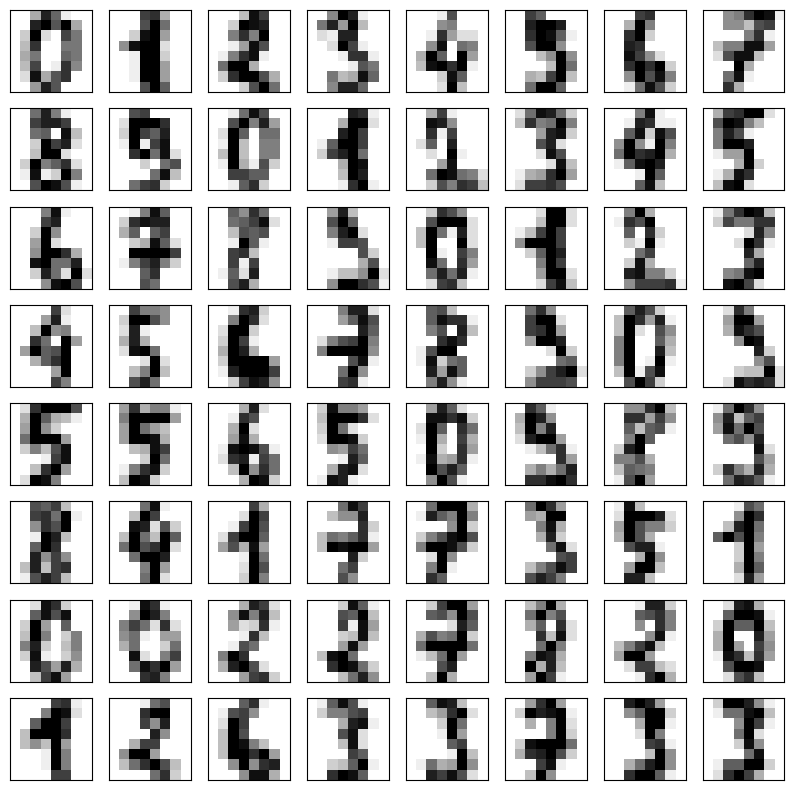

In [32]:
# Each Digit is represented in digits.images as a matrix of 8x8 = 64 pixels. Each of the 64 values represent
# a greyscale. The Greyscale are then plotted in the right scale by the imshow method.
fig, ax = plt.subplots(8,8, figsize=(10,10))
for i, axi in enumerate(ax.flat):
    axi.imshow(digits.images[i], cmap='binary')
    axi.set(xticks=[], yticks=[])

**4. Vẽ một ảnh từ ma trận 8 x 8**

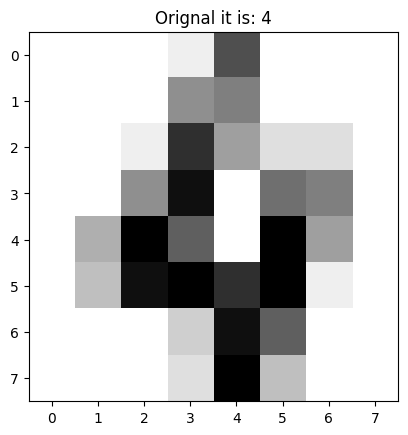

In [33]:
# Hàm vẽ 1 ảnh có kích thước 8 x 8 (ảnh lấy từ ma images)
def view_digit(index):
    plt.imshow(digits.images[index] , cmap = plt.cm.gray_r)
    plt.title('Orignal it is: '+ str(digits.target[index]))
    plt.show()
# vẽ ảnh ở vị trí thứ 4
view_digit(4)

#### Nhiệm vụ 2: Xây dựng mô hình SVM nhận diện chữ viết tay từ 0 – 9
**1. Chuẩn bị dữ liệu và xây dựng mô hình SVM**

In [34]:
# Thực hiện import các thư viện cần thiết để xây dựng mô hình SVM
# Thực hiện bước 1 của nhiệm vụ 1
from sklearn import svm
main_data = digits['data']
targets = digits['target']
svc = svm.SVC(gamma=0.001 , C = 100)
# GAMMA is a parameter for non linear hyperplanes.
# The higher the gamma value it tries to exactly fit the training data set
# C is the penalty parameter of the error term.
# It controls the trade off between smooth decision boundary and classifying the training points correctly.
svc.fit(main_data[:1500] , targets[:1500])
predictions = svc.predict(main_data[1501:])
# list(zip(predictions , targets[1501:]))

**2. Đánh giá hiệu quả mô hình với Confusion Matrix**

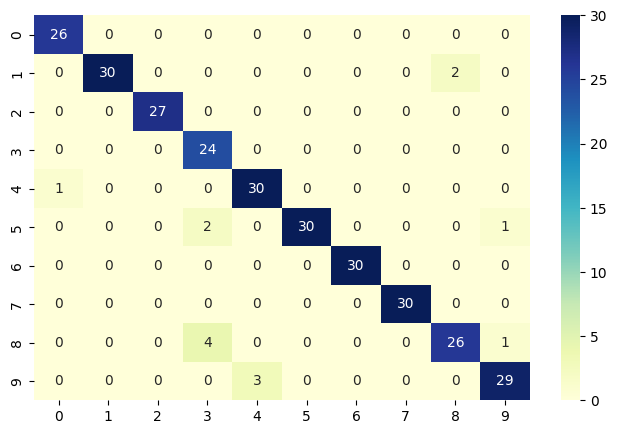

In [35]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
cm = confusion_matrix(predictions, targets[1501:])
conf_matrix = pd.DataFrame(data = cm)
plt.figure(figsize = (8,5))
sns.heatmap(conf_matrix, annot=True,fmt='d',cmap="YlGnBu");

**3. In kết quả dạng văn bản**

In [36]:
from sklearn.metrics import classification_report
print(classification_report(predictions, targets[1501:]))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98        26
           1       1.00      0.94      0.97        32
           2       1.00      1.00      1.00        27
           3       0.80      1.00      0.89        24
           4       0.91      0.97      0.94        31
           5       1.00      0.91      0.95        33
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.93      0.84      0.88        31
           9       0.94      0.91      0.92        32

    accuracy                           0.95       296
   macro avg       0.95      0.96      0.95       296
weighted avg       0.96      0.95      0.95       296



### 2.2.3. Bài tập thực hành 1 — SVM trên dữ liệu bệnh tiểu đường

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# dùng lại Xd_tr, Xd_te, yd_tr, yd_te (đã xử lý ở bài 2.1.4)
# SVM huấn luyện chậm với 80.000 mẫu nên chỉ lấy ngẫu nhiên 10.000 mẫu của tập train để tìm tham số; đánh giá trên toàn bộ tập test
Xs = Xd_tr.sample(10000, random_state=24); ys = yd_tr.loc[Xs.index]
# SVM nhạy với thang đo nên chuẩn hóa bằng StandardScaler
pipe = make_pipeline(StandardScaler(), svm.SVC())
param = {'svc__kernel':['linear','rbf'], 'svc__C':[0.1,1,10], 'svc__gamma':['scale']}
gs_sd = GridSearchCV(pipe, param, cv=3, scoring='accuracy')
gs_sd.fit(Xs, ys)
print("Tham số tốt nhất:", gs_sd.best_params_)
print("Accuracy CV: %.4f" % gs_sd.best_score_)
pred = gs_sd.predict(Xd_te)
print("Accuracy test: %.4f" % accuracy_score(yd_te, pred))
print(confusion_matrix(yd_te, pred))
print(classification_report(yd_te, pred))

Tham số tốt nhất: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Accuracy CV: 0.9596


Accuracy test: 0.9608
[[18221    79]
 [  705   995]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.93      0.59      0.72      1700

    accuracy                           0.96     20000
   macro avg       0.94      0.79      0.85     20000
weighted avg       0.96      0.96      0.96     20000



### 2.2.4. Bài tập thực hành 2 — SVM trên dữ liệu các con thú (Animal Condition)

In [38]:
from sklearn.preprocessing import OneHotEncoder
animal = pd.read_csv('data/Animal-Condition-Predict.csv')
print(animal.shape)
print(animal.isnull().sum())
print(animal['Dangerous'].value_counts())
animal = animal.dropna(subset=['Dangerous'])      # bỏ 2 dòng thiếu nhãn
Xa = animal.drop(columns='Dangerous'); ya = animal['Dangerous']
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, random_state=42, stratify=ya)
# Tất cả đặc trưng là biến phân loại nên mã hóa one-hot trước khi đưa vào SVM
pipe_a = make_pipeline(OneHotEncoder(handle_unknown='ignore'), svm.SVC())
param_a = {'svc__kernel':['linear','rbf'], 'svc__C':[0.1,1,10,100]}
gs_a = GridSearchCV(pipe_a, param_a, cv=5, scoring='accuracy')
gs_a.fit(Xa_tr, ya_tr)
print("Tham số tốt nhất:", gs_a.best_params_, " Accuracy CV: %.4f" % gs_a.best_score_)
pred = gs_a.predict(Xa_te)
print("Accuracy test: %.4f" % accuracy_score(ya_te, pred))
print(confusion_matrix(ya_te, pred))
print(classification_report(ya_te, pred, zero_division=0))

(871, 7)
AnimalName    0
symptoms1     0
symptoms2     0
symptoms3     0
symptoms4     0
symptoms5     0
Dangerous     2
dtype: int64
Dangerous
Yes    849
No      20
Name: count, dtype: int64


Tham số tốt nhất: {'svc__C': 1, 'svc__kernel': 'linear'}  Accuracy CV: 0.9871
Accuracy test: 1.0000
[[  4   0]
 [  0 170]]
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         4
         Yes       1.00      1.00      1.00       170

    accuracy                           1.00       174
   macro avg       1.00      1.00      1.00       174
weighted avg       1.00      1.00      1.00       174



## 2.3. GIẢI THUẬT 3: BAYES NGÂY THƠ (NAÏVE BAYES)
### 2.3.2. Bài làm mẫu — Bài toán 1: phát hiện email spam
#### Nhiệm vụ 1: Phân loại sử dụng Naïve Bayes
**1. Import thư viện và nạp dữ liệu**

In [39]:
#Importing the Necessary libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
data = pd.read_csv('data/spam.csv', encoding='latin-1')   # [Chỉnh] đọc từ thư mục data/
#display the first 5 rows
data.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


**2. Xử lý dữ liệu trước khi xây dựng mô hình**

In [40]:
# Drop the columns with NaN values
# [Chỉnh] file spam.csv tải về chỉ có 2 cột (Category, Message), không có các cột 'Unnamed' như bản trong đề
data = data.drop(columns=[c for c in data.columns if c.startswith('Unnamed')], axis=1)
# Rename columns for clarity:
data.columns = ['label', 'text']
# Separate features (X) and target labels (y)
X = data.drop('label', axis=1)
y = data['label']
# Split the data into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**3. Vector hóa nội dung HAM | SPAM của tập train và tập test**

In [41]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()
# Fit and transform the training data (X_train)
X_train_vectorized = vectorizer.fit_transform(X_train['text'])
# Transform the test data (X_test)
X_test_vectorized = vectorizer.transform(X_test['text'])

**4. Xây dựng mô hình Naïve Bayes**

In [42]:
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()
classifier.fit(X_train_vectorized, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


**5. Đánh giá hiệu quả của mô hình**

In [43]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# Make predictions on the test data
y_pred = classifier.predict(X_test_vectorized)
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(classification_rep)

Accuracy: 0.99
Confusion Matrix:
[[966   0]
 [  8 141]]
Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       966
        spam       1.00      0.95      0.97       149

    accuracy                           0.99      1115
   macro avg       1.00      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115



### 2.3.3. Bài tập thực hành 1 — Naïve Bayes trên dữ liệu hành vi khách hàng (Customer Behaviour)

In [44]:
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
cust = pd.read_csv('data/Customer_Behaviour.csv')
print(cust.shape)
print(cust.isnull().sum().sum(), "giá trị thiếu")
print(cust['Purchased'].value_counts())
cust.head()

(400, 5)
0 giá trị thiếu
Purchased
0    257
1    143
Name: count, dtype: int64


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [45]:
# Đặc trưng: Age, EstimatedSalary; nhãn: Purchased (khách có mua hàng hay không)
Xc = cust[['Age','EstimatedSalary']].values
yc = cust['Purchased'].values
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, random_state=0, stratify=yc)
# Chuẩn hóa đặc trưng (fit trên tập train)
sc = StandardScaler()
Xc_tr = sc.fit_transform(Xc_tr); Xc_te = sc.transform(Xc_te)
gnb_c = GaussianNB()
gnb_c.fit(Xc_tr, yc_tr)
pred = gnb_c.predict(Xc_te)
print("Accuracy test: %.4f" % accuracy_score(yc_te, pred))
print(confusion_matrix(yc_te, pred))
print(classification_report(yc_te, pred, target_names=['Not purchased','Purchased']))

Accuracy test: 0.8500
[[58  6]
 [ 9 27]]
               precision    recall  f1-score   support

Not purchased       0.87      0.91      0.89        64
    Purchased       0.82      0.75      0.78        36

     accuracy                           0.85       100
    macro avg       0.84      0.83      0.83       100
 weighted avg       0.85      0.85      0.85       100



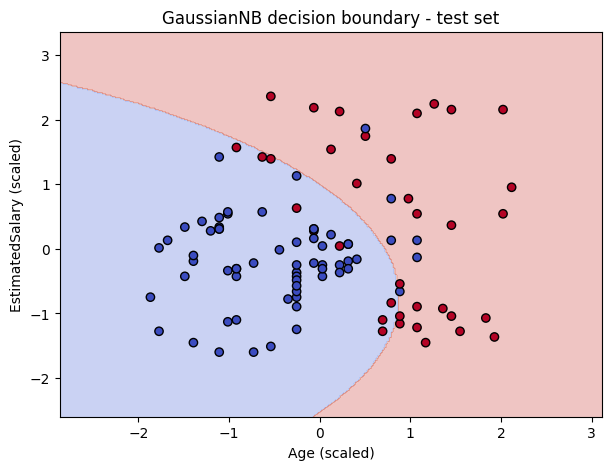

In [46]:
# Biên quyết định của Gaussian Naïve Bayes trên dữ liệu test (2 đặc trưng đã chuẩn hóa)
import matplotlib.pyplot as plt
xx, yy = np.meshgrid(np.linspace(Xc_te[:,0].min()-1, Xc_te[:,0].max()+1, 300),
                     np.linspace(Xc_te[:,1].min()-1, Xc_te[:,1].max()+1, 300))
zz = gnb_c.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(7,5))
plt.contourf(xx, yy, zz, alpha=0.3, cmap='coolwarm')
plt.scatter(Xc_te[:,0], Xc_te[:,1], c=yc_te, cmap='coolwarm', edgecolor='k')
plt.xlabel('Age (scaled)'); plt.ylabel('EstimatedSalary (scaled)')
plt.title('GaussianNB decision boundary - test set')
plt.show()

### 2.3.4. Bài tập thực hành 2 — Naïve Bayes trên tập dữ liệu Mushroom

In [47]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
mush = pd.read_csv('data/mushrooms.csv')      # cột class: e = ăn được, p = độc
print(mush.shape); print(mush['class'].value_counts())
Xm = mush.drop(columns='class'); ym = mush['class']
enc = OrdinalEncoder()
Xm_enc = enc.fit_transform(Xm).astype(int)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm_enc, ym, test_size=0.2, random_state=42, stratify=ym)
cnb = CategoricalNB(min_categories=[len(c) for c in enc.categories_])
cnb.fit(Xm_tr, ym_tr)
pred = cnb.predict(Xm_te)
print("Accuracy test: %.4f" % accuracy_score(ym_te, pred))
print(confusion_matrix(ym_te, pred))
print(classification_report(ym_te, pred, target_names=['edible (e)','poisonous (p)']))

(8124, 23)
class
e    4208
p    3916
Name: count, dtype: int64
Accuracy test: 0.9458
[[835   7]
 [ 81 702]]
               precision    recall  f1-score   support

   edible (e)       0.91      0.99      0.95       842
poisonous (p)       0.99      0.90      0.94       783

     accuracy                           0.95      1625
    macro avg       0.95      0.94      0.95      1625
 weighted avg       0.95      0.95      0.95      1625

